# Cuba river systems in the ONEI river list

Combine Cuba’s published **river centerlines**, **catchment polygons** and
**water geographic names** with the river list from **ONEI** (*Oficina Nacional
de Estadística e Información*). The example produces a numbered reference table
and a map of the complete river systems associated with those entries.

A river system includes its main course and connected tributaries. Its watershed
is the area draining into that network. Several named rivers can belong to one
system, so several table numbers can appear together on the map.

Open this notebook from a local copy of the repository and run the cells in order
using **Pandas**, **GeoPandas**, **PyArrow** and **Matplotlib**. Set the working
directory to `examples/`. All data is loaded locally; no online basemap is required.

For a general map of the hydrography datasets, see [the hydrography map](hydrography_map.ipynb).


## Load the data

The example reads these published products:

- [River centerlines](../data/river-centerlines/): drainage-network lines, downstream connections, stream order and name references.
- [River catchments](../data/river-catchments/): the contributing area associated with each reach.
- [Water geographic names](../data/water-geographic-names/): preferred names, alternatives and detailed feature types.
- [Land polygons](../data/land-polygons/): the geographic background for the map.
- [ONEI river reference](../reference/cuba_onei_river_correspondence.csv): ONEI names, provinces, drainage coasts and reported lengths.
- [Water-name reference](../reference/cuba_water_names_reference.csv): province context for the named features.

GeoParquet preserves the geometry and coordinate reference system. The compressed
catchment file is opened with Python’s `gzip` module before GeoPandas reads it.
The spatial products use **EPSG:4326**, WGS 84 longitude and latitude in degrees.


In [1]:
from pathlib import Path
import gzip
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from collections import defaultdict, deque
import json

ROOT = Path("..")
names = pd.read_parquet(ROOT / "data/water-geographic-names/cuba_water_geographic_names.parquet")
name_reference = pd.read_csv(ROOT / "reference/cuba_water_names_reference.csv").fillna("")
rivers = gpd.read_parquet(ROOT / "data/river-centerlines/cuba_river_centerlines.parquet")
with gzip.open(ROOT / "data/river-catchments/cuba_river_catchments.parquet.gz", "rb") as file:
    catchments = gpd.read_parquet(file)
land = gpd.read_parquet(ROOT / "data/land-polygons/cuba_land_polygons.parquet")

## Read the ONEI reference

Read the published correspondence before exploring the river network. The table
shows the geographic name, ONEI name, province, drainage coast (*vertiente*) and
reported length in kilometres. Numbers connect ONEI entries to the map; they are
local labels for this example.

The reference contains inferred matches for all 39 ONEI entries, including
Mani-Mani and Sagua de Tánamo. The names workflow checks province coverage over
the complete connected system, rather than the local extent carrying a name.
The following cells use those published links directly; matching diagnostics
remain in the workflow audit.


In [2]:
onei = pd.read_csv(ROOT / "reference/cuba_onei_river_correspondence.csv")
reference = pd.DataFrame({
    "Number": range(1, len(onei) + 1),
    "Geographic name": onei["Our river accepted name"],
    "ONEI name": onei["ONEI river"],
    "ONEI description": (onei["ONEI province"] + "; vertiente "
        + onei["ONEI drainage coast"] + "; "
        + onei["ONEI length (km)"].map(lambda length: f"{length:g}") + " km"),
})
display(HTML(reference.fillna("").to_html(index=False)))


Number,Geographic name,ONEI name,ONEI description
1,Río Mantua,Mantua,Pinar del Río; vertiente Norte; 69 km
2,Río Mani-Mani,Mani-Mani,Artemisa; vertiente Norte; 43.3 km
3,Río Almendares,Almendares,La Habana; vertiente Norte; 49.8 km
4,Río Jaruco,Jaruco,Mayabeque; vertiente Norte; 31 km
5,Río La Palma,La Palma,Matanzas; vertiente Norte; 71 km
6,Río Sagua La Grande,Sagua la Grande,Villa Clara; vertiente Norte; 163 km
7,Río Sagua la Chica,Sagua la Chica,Villa Clara; vertiente Norte; 91 km
8,Río Jatibonico del Norte,Jatibonico del Norte,Sancti Spíritus; vertiente Norte; 66.6 km
9,Río Chambas,Chambas,Ciego de Ávila; vertiente Norte; 68.3 km
10,Río Caonao,Caonao,Camagüey; vertiente Norte; 154.9 km


## Create the map

Prepare the complete river systems and their watersheds, then draw the numbered map.


### Follow the river network

`STRM_ID` identifies a reach and `STRM_DN` identifies the next reach downstream.
Following these connections locates the full system outlet independently of
where a particular name is assigned. Catchments join through `STRM_ID`.


In [3]:
# Follow the full physical network to each system outlet.
reaches = rivers.set_index("STRM_ID")
down = reaches.STRM_DN.to_dict()
up = defaultdict(list)
for rid, downstream in down.items():
    if downstream in down:
        up[downstream].append(rid)

terminal = {}
for start in down:
    path, rid = [], start
    while rid in down and rid not in terminal:
        path.append(rid)
        rid = down[rid]
    outlet = terminal[rid] if rid in terminal else path[-1]
    terminal.update({member: outlet for member in path})


### Locate the referenced rivers in the network

Join each ONEI entry’s published name-object identifier to the centerlines’
`gazetteer_id` and `alternative_gazetteer_ids`. Use those reaches to locate the
complete connected system. An ambiguous system stays unselected.

The published name matches remain inferred associations; they do not constitute
independent verification of ONEI river identities. See the
[reference guidance](../reference/README.md) for the matching method.


In [4]:
# Use the published correspondence; do not rematch names in the example.
assigned = defaultdict(set)
for reach in rivers.itertuples():
    ids = json.loads(reach.alternative_gazetteer_ids)
    if pd.notna(reach.gazetteer_id):
        ids.append(reach.gazetteer_id)
    for oid in ids:
        assigned[oid].add(reach.STRM_ID)
objects = names.set_index("id")

selections = []
for number, (_, row) in enumerate(onei.iterrows(), 1):
    oid = row["Our river object ID"]
    options = {terminal[rid] for rid in assigned[oid]}
    outlet = next(iter(options)) if len(options) == 1 else None
    selections.append({
        "Number": number,
        "Geographic name": objects.at[oid, "preferred_name"] if pd.notna(oid) else "",
        "name_object_id": oid,
        "ONEI name": row["ONEI river"],
        "ONEI description": reference.iloc[number - 1]["ONEI description"],
        "outlet": outlet,
    })
selected = pd.DataFrame(selections)


### Assemble complete river systems and watersheds

Follow each located course downstream to its system outlet, then collect every
reach draining to that outlet. This includes unnamed tributaries and reaches
with other names. Combine their catchment polygons to obtain the watershed.

The resulting `network` contains all selected centerlines, and `watersheds`
contains one polygon record per distinct system outlet. Shared systems are drawn
once, while their individual ONEI entries remain separate in the table.


In [5]:
# Include every upstream reach and catchment, regardless of its assigned name.
watershed_reaches = {}
selected["system_outlet"] = selected.outlet.map(
    lambda outlet: terminal[int(outlet)] if pd.notna(outlet) else None)
for outlet in selected.system_outlet.dropna().astype(int).unique():
    members, pending = set(), [outlet]
    while pending:
        rid = pending.pop()
        members.add(rid)
        pending.extend(up[rid])
    watershed_reaches[outlet] = members
connected = set().union(*watershed_reaches.values())
network = rivers.loc[rivers.STRM_ID.isin(connected)]
watersheds = gpd.GeoDataFrame([
    {"outlet": outlet, "geometry": catchments.loc[catchments.STRM_ID.isin(members)].geometry.union_all()}
    for outlet, members in watershed_reaches.items()], crs=catchments.crs)

### Draw the map

Pale green polygons show the complete watersheds. Thin blue lines show every
reach in each selected system; orders **3–7** use progressively thicker lines.
Numbers refer to the table above. A combined numeric label means several ONEI
rivers belong to the same system. No legend is displayed.

Adjust the plotting options below to change the appearance. Uncomment
`fig.savefig(...)` to save the map as `examples/onei_river_systems.png`.


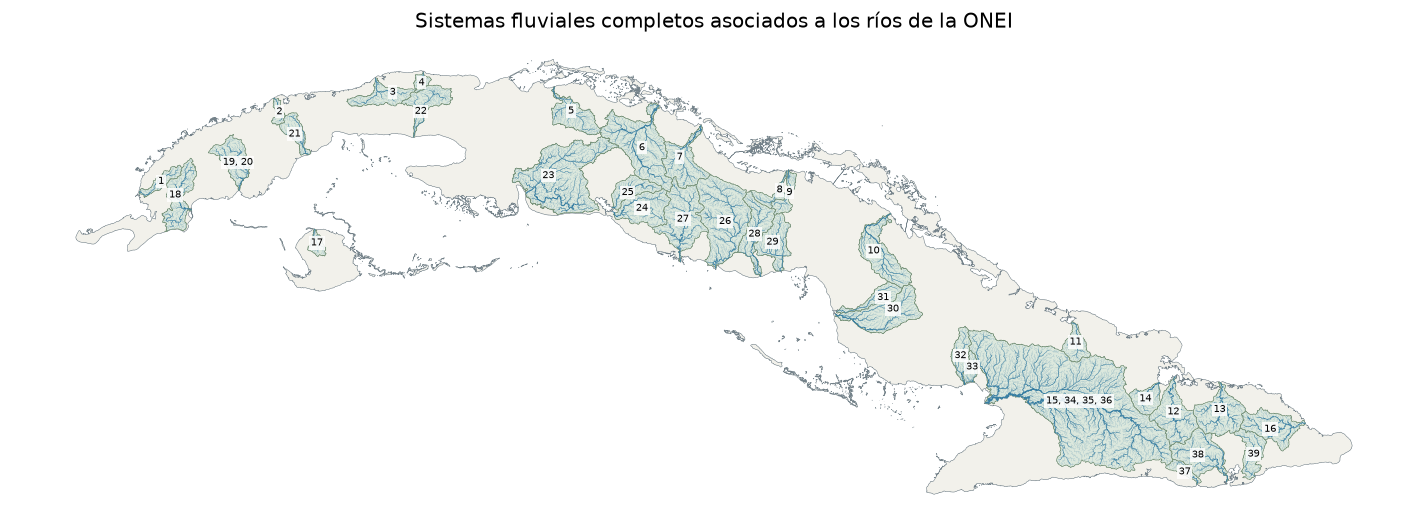

In [6]:
watershed_points = watersheds.set_index("outlet").geometry.representative_point()

fig, ax = plt.subplots(figsize=(12, 9))
land.plot(ax=ax, color="#F2F1EB", edgecolor="#74828A", linewidth=0.25)
watersheds.plot(ax=ax, color="#DCE8DD", edgecolor="#79947C", linewidth=0.35)
network.plot(ax=ax, color="#79A8BD", linewidth=0.10)
for order, width in {3: 0.20, 4: 0.30, 5: 0.45, 6: 0.65, 7: 0.90}.items():
    network.loc[network.ORD_STRAH.eq(order)].plot(ax=ax, color="#397FA3", linewidth=width)
for outlet, group in selected.dropna(subset=["system_outlet"]).groupby("system_outlet"):
    point = watershed_points.loc[int(outlet)]
    label = ", ".join(group.Number.astype(str))
    ax.text(point.x, point.y, label, fontsize=6, ha="center", va="center",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1), zorder=5)
ax.set_title("Sistemas fluviales completos asociados a los ríos de la ONEI")
ax.set_axis_off()
fig.tight_layout()
plt.show()

# fig.savefig(ROOT / "examples/onei_river_systems.png", dpi=220, bbox_inches="tight")